# 05 · Experiment C: fusion within the CQI cupping database (RQ4)

**Target.** Three quality classes from tertiles of the total cup score (HQ ≥ 83.17, AQ 81.67–83.17, LQ < 81.67), mirroring S1's HQ/AQ/LQ.

**Sources.** G1 = the 10 sensory scores (the total *is* their sum, so G1 is only an upper bound), G2 = physical/bean data, G3 = origin. **C1** concatenates the encoded G2 + G3 columns, **C2** uses per-group PCA embeddings, **C3** trains one model per group and combines the decisions. Imputation, encoding and PCA are fitted in-fold. Code: `src/experiments/expC_cqi.py`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 3)
R = ROOT / 'results'; F = R / 'figures'; A = R / 'ablations'
def show(p, w=650):
    p = Path(p)
    display(Image(filename=str(p), width=w)) if p.exists() else print('missing figure:', p.name)
def table(p, **kw):
    p = Path(p)
    return pd.read_csv(p, **kw) if p.exists() else print('missing table:', p.name)

In [2]:
c = table(R / 'expC_cqi_fusion.csv')
c[['level','variant','accuracy_mean','accuracy_std','balanced_accuracy_mean','macro_f1_mean']].sort_values(['level','accuracy_mean'], ascending=[True, False])

,level,variant,accuracy_mean,accuracy_std,balanced_accuracy_mean,macro_f1_mean
28,C1,C1|SVM,0.496,0.013,0.491,0.480
0,C1,C1|LR,0.491,0.010,0.491,0.484
36,C1,C1|MLP,0.489,0.009,0.486,0.485
10,C1,C1|RF,0.477,0.008,0.474,0.473
20,C1,C1|GB,0.456,0.006,0.454,0.454
37,C2,C2|MLP,0.481,0.015,0.476,0.464
29,C2,C2|SVM,0.476,0.010,0.470,0.450
11,C2,C2|RF,0.471,0.005,0.469,0.468
1,C2,C2|LR,0.467,0.009,0.462,0.447
21,C2,C2|GB,0.452,0.015,0.450,0.450


In [3]:
table(R / 'expC_significance.csv')

,A,B,acc_A,acc_B,wilcoxon_p
0,C1|SVM,C2|MLP,0.496,0.481,0.438
1,C1|SVM,C3|LR|vote,0.496,0.498,0.812
2,C2|MLP,C3|LR|vote,0.481,0.498,0.062


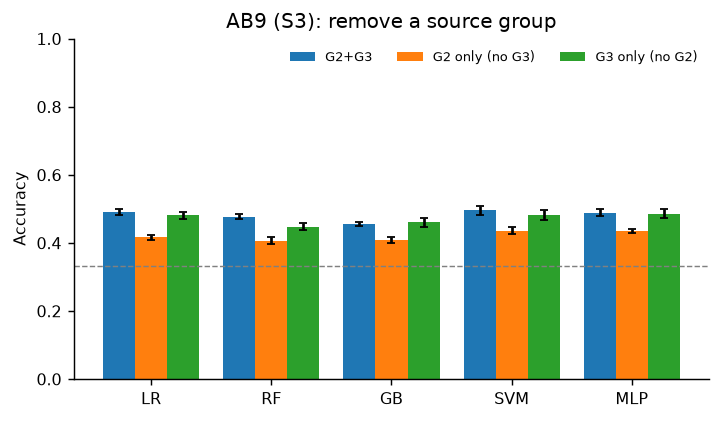

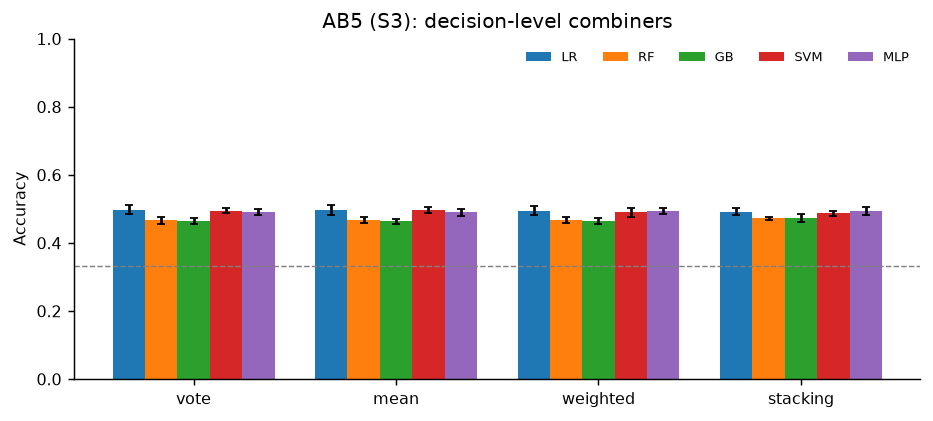

In [4]:
show(F / 'AB9_group_removal_S3.png', 700); show(F / 'AB5_combiners_S3.png', 700)

## What do the quality grades mean in cupping terms?

In [5]:
table(R / 'expC_quality_profile_all.csv', index_col=0)

,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points,Moisture,Category.One.Defects,Category.Two.Defects,Quakers,altitude_mean_meters,n
quality,,,,,,,,,,,,,,,,,
HQ,7.807,7.806,7.691,7.794,7.744,7.800,9.963,9.986,9.959,7.836,84.387,0.081,0.281,2.732,0.165,1425.299,481
AQ,7.559,7.538,7.412,7.521,7.508,7.529,9.940,9.967,9.927,7.518,82.419,0.089,0.348,2.984,0.224,1308.962,425
LQ,7.325,7.203,7.085,7.281,7.292,7.211,9.611,9.560,9.696,7.136,79.398,0.096,0.831,5.042,0.134,1237.437,432


In [6]:
table(R / 'expC_quality_profile_colombia.csv', index_col=0)

,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points,n
quality,,,,,,,,,,,,
HQ,7.738,7.684,7.615,7.679,7.709,7.797,9.993,10.000,10.000,7.713,83.929,103
AQ,7.550,7.507,7.441,7.463,7.490,7.628,9.979,9.990,10.000,7.527,82.578,64
LQ,7.516,7.401,7.276,7.178,7.448,7.459,9.376,9.417,9.459,7.400,79.927,16


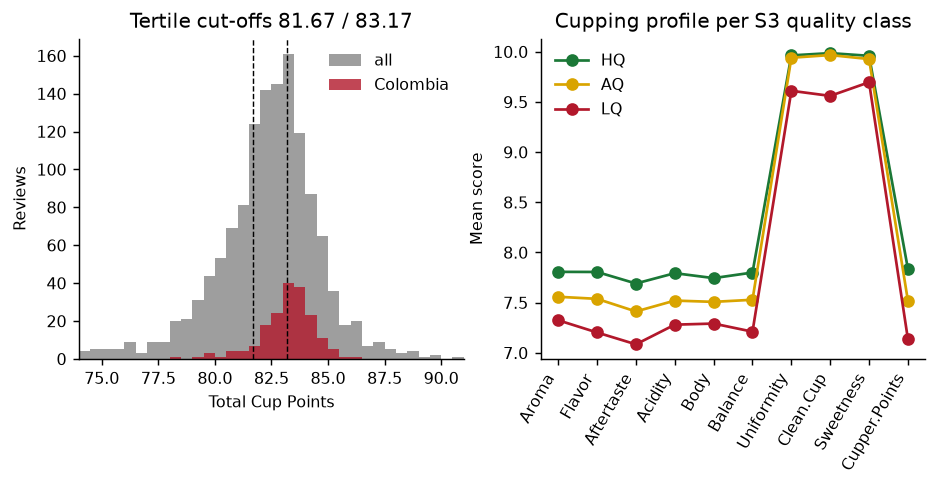

In [7]:
show(F / 'expC_quality_grades.png', 850)